# 03 · Realistic Backtest — model signals vs Buy & Hold

Uses **vectorbt** to simulate the frozen strategy from `02_modeling` (`outputs/frozen_config.json`).

**Execution assumptions (fixed in the plan, not tuned on test):**
- Signal produced after the close of day *t* → order filled at the **open of day t+1** (vectorbt `price=Open`, signals shifted one bar).
- **Fees 0.1% per side + slippage 0.05% per side** (a round trip costs ≈ 0.3%).
- Long-only primary strategy: Buy → long 100% of equity, Sell → flat (cash), Hold → keep the current position. Cash earns 0%.
- Initial capital USD 100,000; benchmark = Buy & Hold SPY over the same period with the same costs.
- Test period 2023-01-03 → 2024-12-31. The validation period (2021–2022) is shown only for context — that is where the signal rule was chosen.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.data import load_snapshot
from src.dataset import build_dataset
from src.models import MomentumRule
from src.backtest import apply_rule, to_positions, run_backtest, buy_and_hold, summarize

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
def savefig(name): plt.savefig(config.FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

raw = load_snapshot(); prices = raw[["Open", "Close"]]
ds = build_dataset(raw)
FROZEN = json.loads((config.OUTPUT_DIR / "frozen_config.json").read_text())
RULE = FROZEN["signal_rule"]
pred_te = pd.read_csv(config.OUTPUT_DIR / "test_predictions.csv", index_col=0, parse_dates=True)
pred_va = pd.read_csv(config.OUTPUT_DIR / "val_predictions.csv", index_col=0, parse_dates=True)
print("Frozen model:", FROZEN["experiment"], FROZEN["model"], "| rule:", RULE)
print("Test signals:", pred_te.index.min().date(), "→", pred_te.index.max().date(), len(pred_te), "days")
pred_te["action"].map(config.CLASS_NAMES).value_counts()

Frozen model: E06 RF | rule: {'margin': 0.05, 'min_hold': 5}
Test signals: 2023-01-03 → 2024-12-31 502 days


action
Hold    227
Sell    143
Buy     132
Name: count, dtype: int64

## 1. Strategies on the test period

In [2]:
def proba_frame(p):
    return p[["p_Sell", "p_Hold", "p_Buy"]].set_axis([-1, 0, 1], axis=1)

def strategies(pred, fees=config.FEES, slippage=config.SLIPPAGE):
    proba = proba_frame(pred)
    days = pred.index
    period = prices.loc[days.min():days.max()]
    mom = pd.Series(MomentumRule().fit(None, None).predict(ds.loc[days]), index=days)
    acts = {
        "Model · frozen rule (long-only)": to_positions(apply_rule(proba, RULE["margin"]), min_hold=RULE["min_hold"]),
        "Model · raw argmax (long-only)": to_positions(apply_rule(proba, None)),
        "Model · frozen rule (long/short)": to_positions(apply_rule(proba, RULE["margin"]), long_short=True, min_hold=RULE["min_hold"]),
        "B3 momentum rule (long-only)": to_positions(mom),
    }
    pfs = {k: run_backtest(v, prices, fees, slippage) for k, v in acts.items()}
    pfs["Buy & Hold SPY"] = buy_and_hold(period, fees, slippage)
    return pfs, acts

pfs_te, pos_te = strategies(pred_te)
res_te = pd.DataFrame([summarize(pf, k) for k, pf in pfs_te.items()]).set_index("strategy")
res_te

,total_return,cagr,ann_vol,sharpe,max_drawdown,calmar,n_orders,n_trades,exposure,total_fees,final_value
strategy,,,,,,,,,,,
Model · frozen rule (long-only),0.2371,0.1127,0.0977,1.1420,-0.0959,1.1760,30,15,0.5800,3236.9400,123713.6600
Model · raw argmax (long-only),0.2719,0.1283,0.0923,1.3550,-0.0775,1.6550,56,28,0.5500,6311.2000,127189.7700
Model · frozen rule (long/short),-0.0906,-0.0466,0.1326,-0.2930,-0.2659,-0.1750,31,31,0.9980,5441.7300,90935.2400
B3 momentum rule (long-only),0.3767,0.1741,0.1232,1.3650,-0.1018,1.7100,5,3,0.9560,491.3600,137666.5800
Buy & Hold SPY,0.5655,0.2523,0.1283,1.8180,-0.0997,2.5300,1,1,1.0000,99.9000,156546.2500


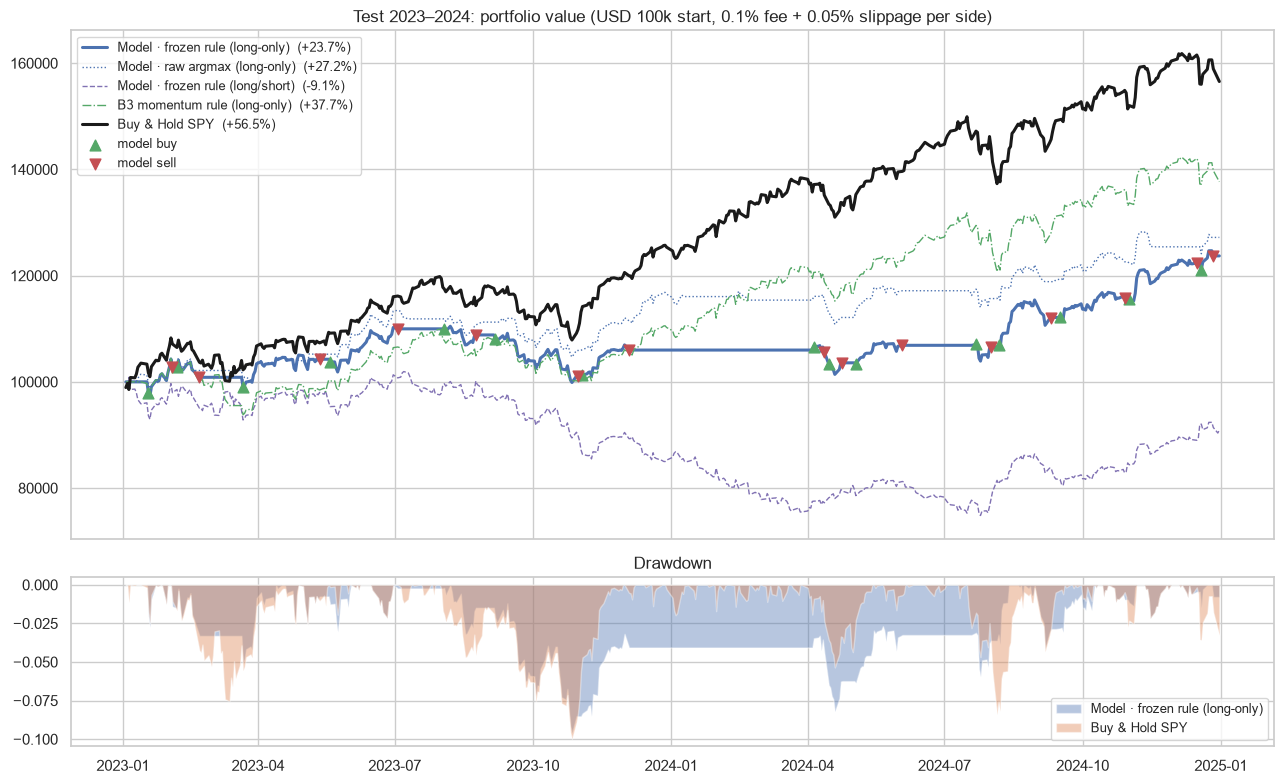

In [3]:
PRIMARY = "Model · frozen rule (long-only)"
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
styles = {PRIMARY: dict(lw=2.2, color="C0"), "Buy & Hold SPY": dict(lw=2.2, color="k"),
          "Model · raw argmax (long-only)": dict(lw=1, color="C0", ls=":"),
          "Model · frozen rule (long/short)": dict(lw=1, color="C4", ls="--"),
          "B3 momentum rule (long-only)": dict(lw=1, color="C2", ls="-.")}
for k, pf in pfs_te.items():
    ax[0].plot(pf.value(), label=f"{k}  ({res_te.loc[k, 'total_return']:+.1%})", **styles[k])
orders = pfs_te[PRIMARY].orders.records_readable
v = pfs_te[PRIMARY].value()
buys, sells = orders[orders["Side"] == "Buy"], orders[orders["Side"] == "Sell"]
ax[0].scatter(buys["Timestamp"], v.loc[buys["Timestamp"]], marker="^", color="g", s=60, zorder=5, label="model buy")
ax[0].scatter(sells["Timestamp"], v.loc[sells["Timestamp"]], marker="v", color="r", s=60, zorder=5, label="model sell")
ax[0].set_title("Test 2023–2024: portfolio value (USD 100k start, 0.1% fee + 0.05% slippage per side)")
ax[0].legend(fontsize=9, loc="upper left")
for k in [PRIMARY, "Buy & Hold SPY"]:
    val_ = pfs_te[k].value(); ax[1].fill_between(val_.index, val_ / val_.cummax() - 1, alpha=0.4, label=k)
ax[1].set_title("Drawdown"); ax[1].legend(fontsize=9)
plt.tight_layout(); savefig("equity_vs_bh"); plt.show()

**Reading (test 2023–2024, after costs).**
| | Return | Sharpe | Max DD | Trades |
|---|---|---|---|---|
| **Buy & Hold SPY** | **+56.5%** | **1.82** | −10.0% | 1 |
| Model · frozen rule (long-only) | +23.7% | 1.14 | −9.6% | 15 |
| Model · raw argmax | +27.2% | 1.36 | −7.8% | 28 |
| B3 momentum rule | +37.7% | 1.37 | −10.2% | 3 |
| Model · long/short | −9.1% | −0.29 | −26.6% | 31 |

- The model **underperforms Buy & Hold by ≈ 33 percentage points** and also loses to the simple momentum rule.
- The biggest single cause is visible on the chart. The model **sold on 4 Dec 2023 and stayed in cash until 5 Apr 2024**, while SPY rose ≈ 14% (fill prices 439 → 500). Over that stretch the rule produced **51 Sell, 30 Hold and 0 Buy** signals. After strong advances (high RSI, %B near the upper band) the forest rates P(Sell) above P(Buy). This is a mild mean-reversion pattern learned in 2010–2020: in training, Sell days follow slightly *stronger* momentum than Buy days (RSI z −0.19 vs −0.28). In a persistent rally that pattern keeps the strategy out of the market.
- Note also that the margin rule ignores P(Hold). The forest's probabilities are compressed (max P(Buy) ≈ 0.48 on test), so small differences between P(Buy) and P(Sell) drive every decision.
- **Long/short loses money.** Sell predictions in a rising market become losing shorts, because Sell precision is low.
- Raw argmax beat the validation-selected rule on test, so the rule selection did **not** generalise (see §8 of `02_modeling`).

## 2. How much do costs matter?
Same signals, different cost levels (fee per side; slippage fixed at 0.05% except in the zero-cost row).

In [4]:
rows = []
for fee in config.FEE_GRID:
    for name in [PRIMARY, "Model · raw argmax (long-only)", "Buy & Hold SPY"]:
        pfs, _ = strategies(pred_te, fees=fee)
        rows.append({"fee_per_side": fee, "strategy": name, **{k: summarize(pfs[name])[k] for k in ["total_return", "sharpe", "n_trades", "total_fees"]}})
pfs0, _ = strategies(pred_te, fees=0.0, slippage=0.0)
for name in [PRIMARY, "Model · raw argmax (long-only)", "Buy & Hold SPY"]:
    rows.append({"fee_per_side": "0 (no slippage)", "strategy": name, **{k: summarize(pfs0[name])[k] for k in ["total_return", "sharpe", "n_trades", "total_fees"]}})
fee_table = pd.DataFrame(rows)
fee_table.pivot(index="fee_per_side", columns="strategy", values="total_return")

strategy,Buy & Hold SPY,Model · frozen rule (long-only),Model · raw argmax (long-only)
fee_per_side,,,
0.0000,0.5670,0.2748,0.3452
0.0005,0.5662,0.2558,0.3080
0.0010,0.5655,0.2371,0.2719
0.0020,0.5639,0.2006,0.2026
0 (no slippage),0.5678,0.2941,0.3834


In [5]:
fee_table.pivot(index="fee_per_side", columns="strategy", values="sharpe")

strategy,Buy & Hold SPY,Model · frozen rule (long-only),Model · raw argmax (long-only)
fee_per_side,,,
0.0000,1.8230,1.3040,1.6640
0.0005,1.8200,1.2230,1.5100
0.0010,1.8180,1.1420,1.3550
0.0020,1.8140,0.9810,1.0440
0 (no slippage),1.8250,1.3840,1.8180


**Reading.**
- At the default 0.1% + 0.05% per side, costs take ≈ 6 pp from the frozen strategy (29.4% → 23.7%) and ≈ 11 pp from raw argmax (38.3% → 27.2%). Higher turnover means more damage: at 0.2% per side the two converge at ≈ 20%.
- **Even with zero costs the model (27–38%) is far below Buy & Hold (57%).** Costs make it worse, but the core problem is the signal: being out of the market in a strong bull market.
- In the validation period, argmax trading paid fees of ≈ 8% of capital. A model that trades often loses to fees, as the brief warns.

## 3. Where did the return go? Invested vs. out-of-market days
Daily SPY open-to-open returns split by whether the primary strategy was in the market on that day.

In [6]:
pos = pos_te[PRIMARY].shift(1).fillna(0)                 # position actually held during day t+1
o2o = prices["Open"].pct_change().shift(-1).reindex(pos.index)   # open(t)->open(t+1), for exposure accounting only
df = pd.DataFrame({"pos": pos, "ret": o2o}).dropna()
summary = df.groupby("pos")["ret"].agg(days="count", mean_daily="mean", compounded=lambda r: (1 + r).prod() - 1)
summary.index = summary.index.map({0: "out of market", 1: "invested"})
display(summary)
top = df["ret"].nlargest(10)
print(f"Of SPY's 10 best days in the test period, the strategy was invested on {int(df.loc[top.index, 'pos'].sum())}.")

,days,mean_daily,compounded
pos,,,
out of market,210,0.0010,0.2194
invested,291,0.0009,0.2941


Of SPY's 10 best days in the test period, the strategy was invested on 5.


**Reading.** The strategy was in the market on 291 days and in cash on 210 days. The average SPY return on its *cash* days (+0.10%/day) is no lower than on its invested days (+0.09%/day). While out, it missed a compounded +21.9%. It was invested on only 5 of the 10 best days. **There is no market-timing skill**: the days it avoided were not worse days. Under that condition, every day out of the market in an up-drifting index has an expected cost.

## 4. Context: validation period (where the signal rule was selected)

,total_return,cagr,ann_vol,sharpe,max_drawdown,calmar,n_orders,n_trades,exposure,total_fees,final_value
strategy,,,,,,,,,,,
Model · frozen rule (long-only),-0.0019,-0.0010,0.1589,0.0730,-0.1725,-0.0060,26,13,0.5090,2727.7200,99808.9500
Model · raw argmax (long-only),-0.0390,-0.0197,0.1520,-0.0550,-0.1742,-0.1130,81,41,0.4890,8266.7200,96101.7900
Model · frozen rule (long/short),-0.0898,-0.0460,0.1941,-0.1460,-0.2053,-0.2240,27,27,0.9980,4993.8100,91022.5800
B3 momentum rule (long-only),0.0104,0.0052,0.1103,0.1020,-0.2306,0.0220,10,5,0.5980,1099.8200,101035.3500
Buy & Hold SPY,0.0477,0.0236,0.1949,0.2170,-0.2450,0.0960,1,1,1.0000,99.9000,104773.3200


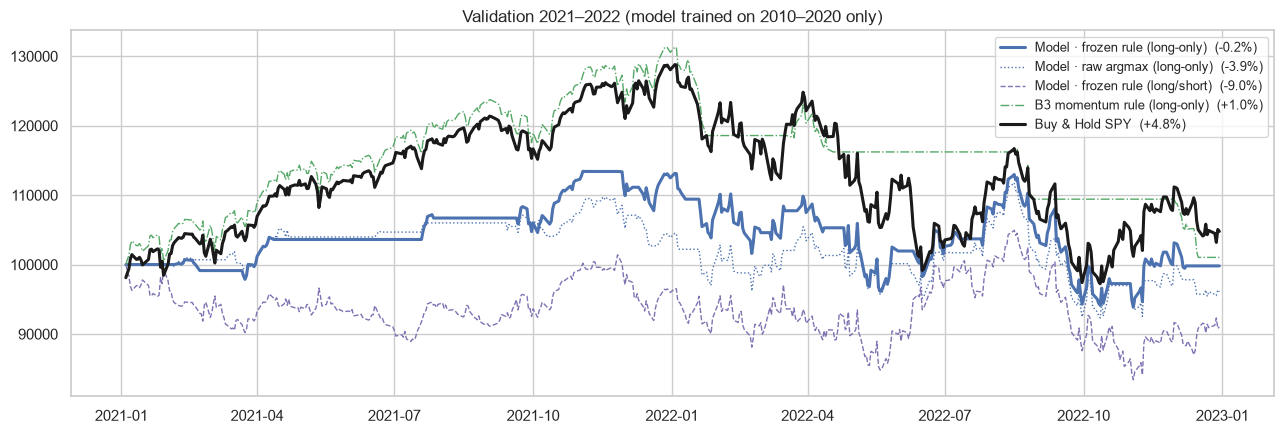

In [7]:
pfs_va, _ = strategies(pred_va)
res_va = pd.DataFrame([summarize(pf, k) for k, pf in pfs_va.items()]).set_index("strategy")
display(res_va)
fig, ax = plt.subplots(figsize=(13, 4.5))
for k, pf in pfs_va.items():
    ax.plot(pf.value(), label=f"{k}  ({res_va.loc[k, 'total_return']:+.1%})", **styles[k])
ax.set_title("Validation 2021–2022 (model trained on 2010–2020 only)"); ax.legend(fontsize=9)
plt.tight_layout(); savefig("equity_validation"); plt.show()

In [8]:
out = {"assumptions": {"fees_per_side": config.FEES, "slippage_per_side": config.SLIPPAGE, "fill": "next open",
                       "init_cash": config.INIT_CASH, "rule": RULE},
       "test": res_te.reset_index().to_dict(orient="records"),
       "validation": res_va.reset_index().to_dict(orient="records"),
       "fee_sensitivity": fee_table.to_dict(orient="records")}
(config.OUTPUT_DIR / "backtest_metrics.json").write_text(json.dumps(out, indent=2, default=str))
print("saved outputs/backtest_metrics.json")

saved outputs/backtest_metrics.json


## Backtest conclusions
1. The classifier beats every naive classification baseline (macro-F1 0.41 vs 0.31), but **that edge does not turn into trading value**. After realistic costs it earns +23.7% vs +56.5% for Buy & Hold in 2023–2024.
2. The edge is "will next week be a big move or a quiet one", not "up or down". A Buy/Sell trading rule needs the direction, which the model does not have.
3. Costs scale with turnover and matter; but even at zero cost the strategy loses, because time out of a rising market is expensive.
4. Choices tuned on two years of validation (the signal rule) did not carry over to the test period. With few trades, backtest-based selection is very noisy.
5. One 2-year bull-market test period is a single realisation. No statement of statistical significance is made, and a different regime (e.g. 2022) would change the ranking. The validation-period table above shows the model losing less than Buy & Hold in drawdown terms, but still earning less.

See `outputs/report.md` for the full Lessons Learned discussion.